<a href="https://colab.research.google.com/github/asteriaji/MSSP6070/blob/main/WeeklyModules/Week08/Jiangyu_Ji_PARTICIPATION_ACTIVITY_Week_8_Plot_a_trendline_over_a_time_series_dataset_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [59]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import statsmodels.formula.api as sm
import statsmodels.api as se
import seaborn as sns
import datetime as dt
from sklearn.linear_model import LinearRegression
from scipy import stats
from io import StringIO
import itertools
import os
import subprocess
from pathlib import Path

pd.set_eng_float_format(accuracy=3, use_eng_prefix=True)
pd.set_option('display.float_format', lambda x: '%.2f' % x)

owner = 'asteriaji'
repository = 'MSSP6070'
repo_url = f'https://github.com/{owner}/{repository}.git'
repo_path = Path('/content') / repository

if not repo_path.exists():
    subprocess.run(
        ['git', 'clone', repo_url, str(repo_path)],
        check=True
    )
else:
    print("Repository already exists. Using the existing copy.")

os.chdir(repo_path)

print("Current directory:", os.getcwd())

print("Files in repository:")
for item in sorted(repo_path.rglob('*')):
    if item.is_file() and '.git' not in item.parts:
        print(item.relative_to(repo_path))

Repository already exists. Using the existing copy.
Current directory: /content/MSSP6070
Files in repository:
Adding_File_Structure.py
Assignment_Template.ipynb
Assignments/.gitkeep
Assignments/Assignment 1/Corrected_Version_Jiangyu_Ji_MSSP_6070_Assignment_1.ipynb
Assignments/Assignment 1/Jiangyu_Ji_MSSP_6070_Assignment_1_260930.ipynb
Assignments/Assignment 2/1
WeeklyModules/.gitkeep
WeeklyModules/Week01/.gitkeep
WeeklyModules/Week01/1_introducing_matplotlib_(1).ipynb
WeeklyModules/Week01/Week1_Jiangyu_Ji_Participation_Activity_Exercises_260828.ipynb
WeeklyModules/Week01/stats_viz (1).py
WeeklyModules/Week02/.gitkeep
WeeklyModules/Week02/Week2_Jiangyu_Ji_Participation_Activity_260907__(2).ipynb
WeeklyModules/Week02/Week_2_Data_Stuctures.ipynb
WeeklyModules/Week03/.gitkeep
WeeklyModules/Week03/Week_3_Jiangyu_Ji_PARTICIPATION_ACTIVITY_(3)_(2).ipynb
WeeklyModules/Week04/.gitkeep
WeeklyModules/Week04/Jiangyu_Ji_Assignment_PARTICIPATION_ACTIVITY_Week_4_Opening_a_CSV_file_and_modifying_the_c

In [60]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
DATA_PATH = repo_path /'data'/'InternetSales.csv'

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Data file not found: {DATA_PATH}"
    )

df = pd.read_csv(DATA_PATH,encoding="latin1")

print("Data loaded successfully!")
print("Data shape:", df.shape)
display(df.head())

Data loaded successfully!
Data shape: (60398, 60)


/tmp/ipykernel_4090/1874161717.py:12: DtypeWarning: Columns (14) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(DATA_PATH,encoding="latin1")


,ID,CustomerKey,GeographyKey,City,CountryRegionCode,EnglishCountryRegionName,CustomerAlternateKey,Title,FirstName,MiddleName,...,ProductStandardCost,TotalProductCost,SalesAmount,TaxAmt,Freight,CarrierTrackingNumber,CustomerPONumber,OrderDate,DueDate,ShipDate
0,0,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1912.15,1912.15,3399.99,272.00,85.00,NaN,NaN,1/19/2011,1/31/2011,1/26/2011
1,1,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1265.62,1265.62,2319.99,185.60,58.00,NaN,NaN,1/18/2013,1/30/2013,1/25/2013
2,2,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,8.22,8.22,21.98,1.76,0.55,NaN,NaN,1/18/2013,1/30/2013,1/25/2013
3,3,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1481.94,1481.94,2384.07,190.73,59.60,NaN,NaN,5/3/2013,5/15/2013,5/10/2013
4,4,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,10.84,10.84,28.99,2.32,0.72,NaN,NaN,5/3/2013,5/15/2013,5/10/2013


In [61]:
date_cols = ["OrderDate", "DueDate", "ShipDate"]

for col in date_cols:
    df[col] = pd.to_datetime(df[col], errors="coerce")

In [62]:
df["Year"] = df["OrderDate"].dt.year
yearly_sales = df.pivot_table(
    index="EnglishCountryRegionName",
    columns="Year",
    values="SalesAmount",
    aggfunc="sum")

print(yearly_sales)

Year                         2010       2011       2012       2013     2014
EnglishCountryRegionName                                                   
Australia                20909.78 2563732.25 2128407.46 4339443.38  8507.72
Canada                    3578.27  571571.80  307604.52 1085632.65  9457.62
France                    3399.99  410845.33  648065.54 1578511.80  3195.06
Germany                       NaN  520500.16  608657.98 1761876.36  3277.83
United Kingdom             699.10  550591.22  712700.96 2124007.29  3713.64
United States            14833.90 2458285.17 1437048.73 5462078.86 17542.85


In [63]:
# Forecast for the next five years (Based on Annual Sales Data)

In [64]:
# After calculating yearly sales by country regions, it shows that
# sales in 2010 and 2014 are substantially lower across all country
# regions. Therefore, further analysis is conducted.

df.groupby("Year")["OrderDate"].agg(
    ["min", "max", "count"])

# The data for 2010 cover only December, while the data for
# 2014 cover only January. As a result, these years have fewer
# observations than the other years.
# Therefore, the lower total sales in these two years may reflect
# the shorter observation periods rather than lower sales performance.

,min,max,count
Year,,,
2010,2010-12-29,2010-12-31,14
2011,2011-01-01,2011-12-31,2216
2012,2012-01-01,2012-12-31,3397
2013,2013-01-01,2013-12-31,52801
2014,2014-01-01,2014-01-28,1970


In [65]:
# Since this analysis focuses on yearly sales, exclude 2010 and 2014 because
# only one quarter of data is available for each year, making them incomplete
# and not directly comparable to the other years.

df_new = df.query(
    '"2011-01-01" <= OrderDate <= "2013-12-31"').copy()

In [66]:
yearly_sales_new = df_new.pivot_table(
    index="EnglishCountryRegionName",
    columns="Year",
    values="SalesAmount",
    aggfunc="sum")

print(yearly_sales_new)

Year                           2011       2012       2013
EnglishCountryRegionName                                 
Australia                2563732.25 2128407.46 4339443.38
Canada                    571571.80  307604.52 1085632.65
France                    410845.33  648065.54 1578511.80
Germany                   520500.16  608657.98 1761876.36
United Kingdom            550591.22  712700.96 2124007.29
United States            2458285.17 1437048.73 5462078.86


In [67]:
Total_yearly_sales_new = (df_new.groupby(["Year"], as_index=False)
    .agg({"SalesAmount": "sum"}))

Total_yearly_sales_new

,Year,SalesAmount
0,2011,7075525.93
1,2012,5842485.20
2,2013,16351550.34


In [68]:
z = np.polyfit(
    Total_yearly_sales_new["Year"],
    Total_yearly_sales_new["SalesAmount"],
    deg=1
)
p = np.poly1d(z)


last_year = int(Total_yearly_sales_new["Year"].max())
future_years = np.arange(last_year + 1, last_year + 6)
forecast_sales = p(future_years)

forecast_df = pd.DataFrame({
    "Year": future_years,
    "ForecastSales": forecast_sales})

display(forecast_df)

,Year,ForecastSales
0,2014,19032544.90
1,2015,23670557.10
2,2016,28308569.31
3,2017,32946581.52
4,2018,37584593.72


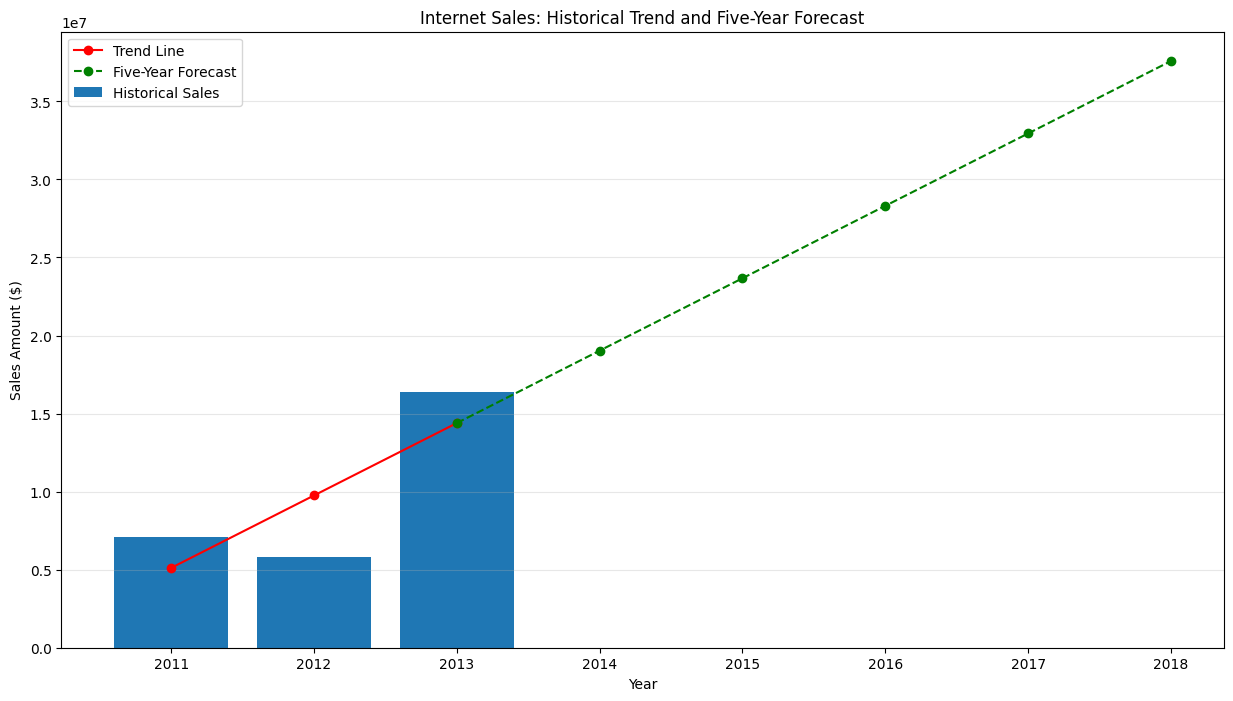

In [69]:
fig = plt.figure(figsize=(15, 8))

plt.bar(
    Total_yearly_sales_new["Year"],
    Total_yearly_sales_new["SalesAmount"],
    label="Historical Sales")

plt.plot(
    Total_yearly_sales_new["Year"],
    p(Total_yearly_sales_new["Year"]),
    color="red",
    marker="o",
    label="Trend Line")

plt.plot(
    np.concatenate(([last_year], future_years)),
    p(np.concatenate(([last_year], future_years))),
    color="green",
    linestyle="--",
    marker="o",
    label="Five-Year Forecast")

plt.xlabel("Year")
plt.ylabel("Sales Amount ($)")
plt.title("Internet Sales: Historical Trend and Five-Year Forecast")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.show()

In [70]:
# Using summary statistics, which product will generate the most sales?

In [71]:
print(df.columns.tolist())

['ID', 'CustomerKey', 'GeographyKey', 'City', 'CountryRegionCode', 'EnglishCountryRegionName', 'CustomerAlternateKey', 'Title', 'FirstName', 'MiddleName', 'LastName', 'NameStyle', 'BirthDate', 'MaritalStatus', 'Suffix', 'Gender', 'EmailAddress', 'YearlyIncome', 'TotalChildren', 'NumberChildrenAtHome', 'EnglishEducation', 'SpanishEducation', 'FrenchEducation', 'EnglishOccupation', 'SpanishOccupation', 'FrenchOccupation', 'HouseOwnerFlag', 'NumberCarsOwned', 'AddressLine1', 'AddressLine2', 'Phone', 'DateFirstPurchase', 'CommuteDistance', 'ProductKey', 'EnglishProductName', 'OrderDateKey', 'DueDateKey', 'ShipDateKey', 'CustomerKey.1', 'PromotionKey', 'CurrencyKey', 'SalesTerritoryKey', 'SalesOrderNumber', 'SalesOrderLineNumber', 'RevisionNumber', 'OrderQuantity', 'UnitPrice', 'ExtendedAmount', 'UnitPriceDiscountPct', 'DiscountAmount', 'ProductStandardCost', 'TotalProductCost', 'SalesAmount', 'TaxAmt', 'Freight', 'CarrierTrackingNumber', 'CustomerPONumber', 'OrderDate', 'DueDate', 'ShipDat

In [72]:
product_sales = (
    df.groupby("EnglishProductName")["SalesAmount"]
      .sum()
      .sort_values(ascending=False))

top_product_sales = product_sales.iloc[0]
total_sales = df["SalesAmount"].sum()
top_product_share = top_product_sales / total_sales * 100

print(f"Top-selling product: {product_sales.index[0]}")
print(f"Product sales: ${top_product_sales:,.2f}")
print(f"Total sales: ${total_sales:,.2f}")
print(f"Share of total sales: {top_product_share:.2f}%")

Top-selling product: Mountain-200 Black, 46
Product sales: $1,373,469.55
Total sales: $29,358,677.22
Share of total sales: 4.68%


In [73]:
# Plot a trend line on the sales (Monthly sales data used)

In [74]:
# Since the five-year forecast uses annual sales data,
# monthly data are used here to examine sales trends in greater detail.
monthly_sales = (
    df.groupby(df["OrderDate"].dt.to_period("M"))["SalesAmount"]
      .sum()
      .reset_index())

monthly_sales["OrderDate"] = monthly_sales["OrderDate"].dt.to_timestamp()
monthly_sales["monthnumber"] = np.arange(len(monthly_sales))

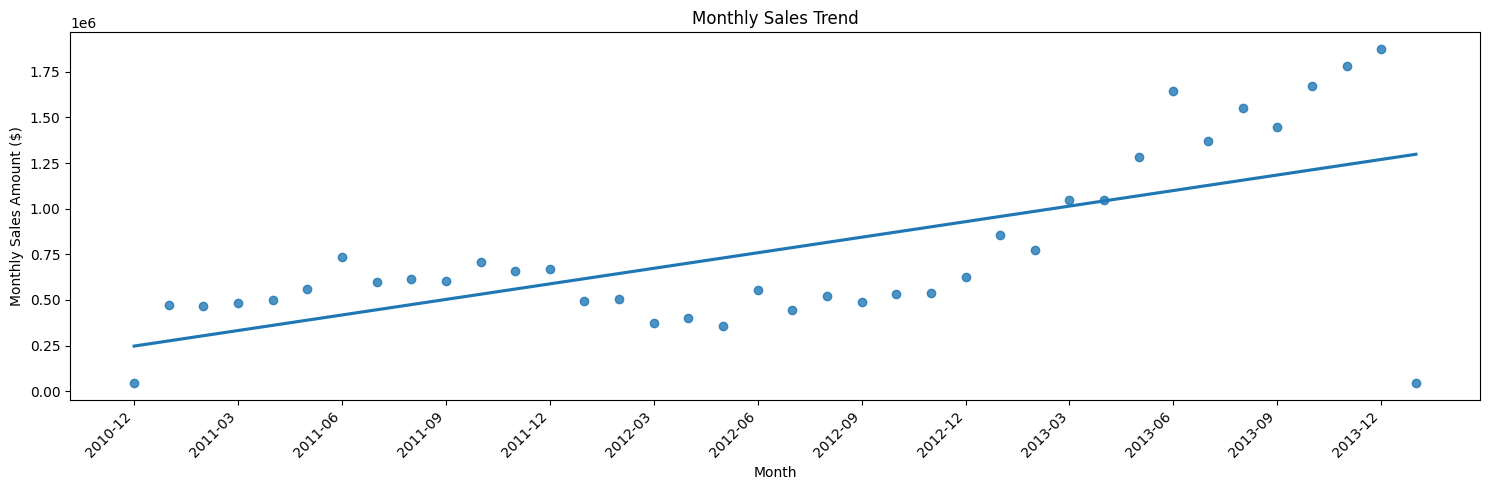

In [75]:
fig, ax1 = plt.subplots(figsize=(15, 5))

sns.regplot(
    data=monthly_sales,
    x="monthnumber",
    y="SalesAmount",
    scatter=True,
    ci=None,
    ax=ax1)

ax1.set(
    title="Monthly Sales Trend",
    xlabel="Month",
    ylabel="Monthly Sales Amount ($)")

tick_positions = monthly_sales["monthnumber"][::3]
tick_labels = monthly_sales["OrderDate"].dt.strftime("%Y-%m")[::3]

ax1.set_xticks(tick_positions)
ax1.set_xticklabels(tick_labels, rotation=45, ha="right")

plt.tight_layout()
plt.show()

# Overall, monthly sales show an upward trend.
# However, sales were relatively low throughout 2012 compared with
# 2011 and 2013.